In [ ]:
from torchvision.datasets import FashionMNIST
from typing import Dict, Tuple
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, transforms
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import numpy as np
from IPython.display import HTML


## Utils


In [2]:
def unorm(x):
  return (x - x.min()) / (x.max() - x.min())


In [ ]:
def plot_sample(samples, n_sample, nrows):
    ncols = n_sample//nrows
    samples = unorm(samples.cpu())
    # Create a figure with subplots
    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 10))

    # Flatten the axes array for easy iteration
    axes = axes.flatten()

    # Loop through each image and plot it
    for i in range(n_sample):
        # Select image
        image = samples[i]

        # Handle grayscale (1 channel) vs RGB (3 channels)
        if image.shape[0] == 1:
            image = image.squeeze(0)
            axes[i].imshow(image, cmap='gray')
        else:
            image = image.permute(1, 2, 0)
            axes[i].imshow(image)

        axes[i].axis('off')  # Hide axis
        axes[i].set_title(f'Image {i + 1}')  # Set title

    # Hide any unused subplots
    for j in range(n_sample, nrows * ncols):
        axes[j].axis('off')

    # Adjust layout
    plt.tight_layout()
    plt.show()


## hyperparameters


In [4]:
# diffusion hyperparameters
timesteps = 1000
beta1 = 1e-4
beta2 = 0.02

# network hyperparameters
device = torch.device("cuda:0" if torch.cuda.is_available() else torch.device('cpu'))
n_feat = 64 # 64 hidden dimension feature
n_cfeat = 10 # context vector is of size 10 (FashionMNIST classes)
height = 32 # 32x32 image
save_dir = '/content/'

# training hyperparameters
batch_size = 100
n_epoch = 10 # Reduced for T4 quick testing if needed, or keep 40. 20 is prob fine.
lrate = 1e-3


## FashionMNIST Dataset


In [5]:
# FashionMNIST download handled by torchvision


100%|██████████| 26.4M/26.4M [00:01<00:00, 14.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.9MB/s]


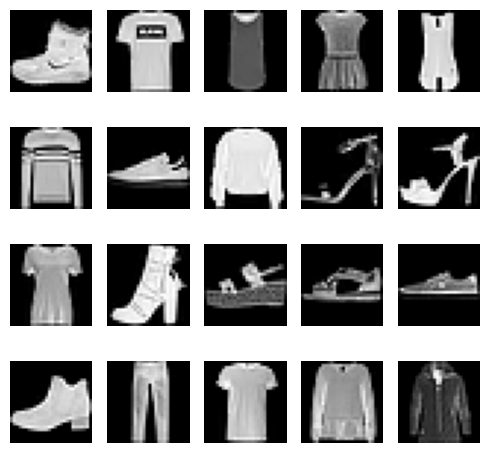

In [6]:
# Download and visualize a few FashionMNIST samples
temp_dataset = FashionMNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
fig, axes = plt.subplots(4, 5, figsize=(5, 5))
axes = axes.flatten()
for i in range(20):
    img, label = temp_dataset[i]
    axes[i].imshow(img.squeeze(), cmap='gray')
    axes[i].axis('off')
plt.tight_layout()
plt.show()


In [7]:
transform = transforms.Compose([
    transforms.Resize((height, height)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


In [8]:
train_dataset = FashionMNIST(root='./data', train=True, download=True, transform=transform)
val_dataset = FashionMNIST(root='./data', train=False, download=True, transform=transform)

# For testing on a smaller subset if needed, otherwise use full
# train_dataset = torch.utils.data.Subset(train_dataset, range(1000))


In [9]:
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)


## UNet


So what model do we use to do this magical 'denoising' step? We've looked a little at basic convolutional neural networks that take in an image and output something like a classification. And we've seen autoencoders that go from an image down to a latent representation and back to an output image. Perhaps one of these would be suitable?


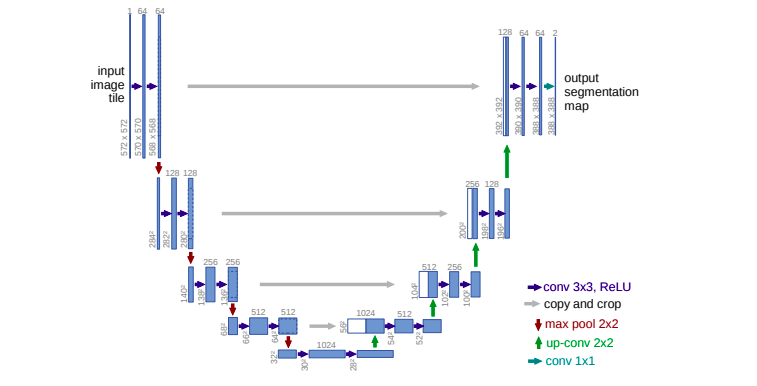

(Unet diagram from [the 2015 paper](https://arxiv.org/abs/1505.04597))


One issue with a typical 'bottlekneck' architecture like an autoencoder is that by design they loose the details around exact pixel coordinates. To get around this, an architecture called the Unet was introduced. Originally designed for segmentation tasks, the architecture (shown above) passes information from high-resolution, early layers to later layers. These 'shortcuts' let the network use detailed features from the original image while also capturing more high-level semantic information from the deeper layers.

These networks turned out to be great at all sorts of image-to-image tasks. Colorization , segmentation and so on. These days, typical unet models incorporate ideas such as attention and can be built around pretrained 'backbones' like resnet-50 for transfer learning tasks.

The implementation below is a fairly typical modern Unet with one extra trick: a TimeEmbedding which encodes the time step (t) and lets the model use this as conditioning information by passing it in in the middle of the network. Take a peek at the code and see if you can figure out roughly what's going on in the forward pass.



In [10]:
class ResidualConvBlock(nn.Module):
    def __init__(
        self, in_channels: int, out_channels: int, is_res: bool = False
    ) -> None:
        super().__init__()

        # Check if input and output channels are the same for the residual connection
        self.same_channels = in_channels == out_channels

        # Flag for whether or not to use residual connection
        self.is_res = is_res

        # First convolutional layer
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, 1, 1),   # 3x3 kernel with stride 1 and padding 1
            nn.BatchNorm2d(out_channels),   # Batch normalization
            nn.GELU(),   # GELU activation function
        )

        # Second convolutional layer
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, 1, 1),   # 3x3 kernel with stride 1 and padding 1
            nn.BatchNorm2d(out_channels),   # Batch normalization
            nn.GELU(),   # GELU activation function
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        # If using residual connection
        if self.is_res:
            # Apply first convolutional layer
            x1 = self.conv1(x)

            # Apply second convolutional layer
            x2 = self.conv2(x1)

            # If input and output channels are the same, add residual connection directly
            if self.same_channels:
                out = x + x2
            else:
                # If not, apply a 1x1 convolutional layer to match dimensions before adding residual connection
                shortcut = nn.Conv2d(x.shape[1], x2.shape[1], kernel_size=1, stride=1, padding=0).to(x.device)
                out = shortcut(x) + x2
            #print(f"resconv forward: x {x.shape}, x1 {x1.shape}, x2 {x2.shape}, out {out.shape}")

            # Normalize output tensor
            return out / 1.414

        # If not using residual connection, return output of second convolutional layer
        else:
            x1 = self.conv1(x)
            x2 = self.conv2(x1)
            return x2

    # Method to get the number of output channels for this block
    def get_out_channels(self):
        return self.conv2[0].out_channels

    # Method to set the number of output channels for this block
    def set_out_channels(self, out_channels):
        self.conv1[0].out_channels = out_channels
        self.conv2[0].in_channels = out_channels
        self.conv2[0].out_channels = out_channels



class UnetUp(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(UnetUp, self).__init__()

        # Create a list of layers for the upsampling block
        # The block consists of a ConvTranspose2d layer for upsampling, followed by two ResidualConvBlock layers
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, 2, 2),
            ResidualConvBlock(out_channels, out_channels),
            ResidualConvBlock(out_channels, out_channels),
        ]

        # Use the layers to create a sequential model
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        # Concatenate the input tensor x with the skip connection tensor along the channel dimension
        x = torch.cat((x, skip), 1)

        # Pass the concatenated tensor through the sequential model and return the output
        x = self.model(x)
        return x


class UnetDown(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(UnetDown, self).__init__()

        # Create a list of layers for the downsampling block
        # Each block consists of two ResidualConvBlock layers, followed by a MaxPool2d layer for downsampling
        layers = [ResidualConvBlock(in_channels, out_channels), ResidualConvBlock(out_channels, out_channels), nn.MaxPool2d(2)]

        # Use the layers to create a sequential model
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        # Pass the input through the sequential model and return the output
        return self.model(x)

class EmbedFC(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedFC, self).__init__()
        '''
        This class defines a generic one layer feed-forward neural network for embedding input data of
        dimensionality input_dim to an embedding space of dimensionality emb_dim.
        '''
        self.input_dim = input_dim

        # define the layers for the network
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
        ]

        # create a PyTorch sequential model consisting of the defined layers
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        # flatten the input tensor
        x = x.view(-1, self.input_dim)
        # apply the model layers to the flattened tensor
        return self.model(x)


In [11]:
class Unet(nn.Module):
    def __init__(self, in_channels, n_feat=256, n_cfeat=10, height=28):  # cfeat - context features
        super(Unet, self).__init__()

        # number of input channels, number of intermediate feature maps and number of classes
        self.in_channels = in_channels
        self.n_feat = n_feat
        self.n_cfeat = n_cfeat
        self.h = height  #assume h == w. must be divisible by 4, so 28,24,20,16...

        # Initialize the initial convolutional layer
        self.init_conv = ResidualConvBlock(in_channels, n_feat, is_res=True)

        # Initialize the down-sampling path of the U-Net with two levels
        self.down1 = UnetDown(n_feat, n_feat)        # down1 #[10, 256, 8, 8]
        self.down2 = UnetDown(n_feat, 2 * n_feat)    # down2 #[10, 256, 4,  4]

         # original: self.to_vec = nn.Sequential(nn.AvgPool2d(7), nn.GELU())
        self.to_vec = nn.Sequential(nn.AvgPool2d((4)), nn.GELU())

        # Embed the timestep and context labels with a one-layer fully connected neural network
        self.timeembed1 = EmbedFC(1, 2*n_feat)
        self.timeembed2 = EmbedFC(1, 1*n_feat)
        self.contextembed1 = EmbedFC(n_cfeat, 2*n_feat)
        self.contextembed2 = EmbedFC(n_cfeat, 1*n_feat)

        # Initialize the up-sampling path of the U-Net with three levels
        # up0 upsamples from 2x2 (after to_vec) to 8x8 (to match down2)
        # Since to_vec uses AvgPool2d(4) on down2 (8x8), output is 2x2
        # To get from 2x2 to 8x8, we need stride 4 (not self.h//4 which is 8)
        self.up0 = nn.Sequential(
            nn.ConvTranspose2d(2 * n_feat, 2 * n_feat, 4, 4), # up-sample from 2x2 to 8x8
            nn.GroupNorm(8, 2 * n_feat), # normalize
            nn.ReLU(),
        )
        self.up1 = UnetUp(4 * n_feat, n_feat)
        self.up2 = UnetUp(2 * n_feat, n_feat)

        # Initialize the final convolutional layers to map to the same number of channels as the input image
        self.out = nn.Sequential(
            nn.Conv2d(2 * n_feat, n_feat, 3, 1, 1), # reduce number of feature maps   #in_channels, out_channels, kernel_size, stride=1, padding=0
            nn.GroupNorm(8, n_feat), # normalize
            nn.ReLU(),
            nn.Conv2d(n_feat, self.in_channels, 3, 1, 1), # map to same number of channels as input
        )

    def forward(self, x, t, c=None):
        """
        x : (batch, n_feat, h, w) : input image
        t : (batch, n_cfeat)      : time step
        c : (batch, n_classes)    : context label
        """
        # x is the input image, c is the context label, t is the timestep, context_mask says which samples to block the context on

        # pass the input image through the initial convolutional layer
        x = self.init_conv(x)
        # pass the result through the down-sampling path
        down1 = self.down1(x)       #[10, 256, 8, 8]
        down2 = self.down2(down1)   #[10, 256, 4, 4]

        # convert the feature maps to a vector and apply an activation
        hiddenvec = self.to_vec(down2)

        # mask out context if context_mask == 1
        if c is None:
            c = torch.zeros(x.shape[0], self.n_cfeat).to(x)

        # embed context and timestep
        cemb1 = self.contextembed1(c).view(-1, self.n_feat * 2, 1, 1)     # (batch, 2*n_feat, 1,1)
        temb1 = self.timeembed1(t).view(-1, self.n_feat * 2, 1, 1)
        cemb2 = self.contextembed2(c).view(-1, self.n_feat, 1, 1)
        temb2 = self.timeembed2(t).view(-1, self.n_feat, 1, 1)
        #print(f"uunet forward: cemb1 {cemb1.shape}. temb1 {temb1.shape}, cemb2 {cemb2.shape}. temb2 {temb2.shape}")


        up1 = self.up0(hiddenvec)
        up2 = self.up1(cemb1*up1 + temb1, down2)  # add and multiply embeddings
        up3 = self.up2(cemb2*up2 + temb2, down1)
        out = self.out(torch.cat((up3, x), 1))
        return out


## Training


In [12]:
# construct model
nn_model = Unet(in_channels=1, n_feat=n_feat, n_cfeat=n_cfeat, height=height).to(device)


In [13]:
#construct optimizer
optim = torch.optim.Adam(nn_model.parameters(), lr=lrate)


We want to set up a "**variance schedule**" β, where $\beta_t$ specifies how much noise we want to add at that step. You get fancy schedules but we'll stick with a linear one for now. \\
At each time step t, the variance of the noise added to the previous step is predetermined by the variance schedule, and it's marked as $\beta_t$, where 0 < $\beta_1$ < $\beta_t$ < $\beta_2$ < 1.


In [14]:
# TODO: complete the code here
# Create Linear Scheduler - beta1 and beta2 are given in the hypermarapeters block
# Linear interpolation of beta values from beta1 to beta2 over timesteps
b_t = torch.linspace(beta1, beta2, timesteps, device=device)
# Compute alpha_t = 1 - beta_t
a_t = 1.0 - b_t
# Compute cumulative product alpha_bar_t = prod(alpha_i) for i=1 to t
a_bar_t = torch.cumprod(a_t, dim=0)


### Forward


Now, we want to train our model at different time steps and we don't particulary want to iterativly add little bits of noise a bunch of times just to train one sample.

Luckily, some smart people did some fancy maths (link https://lilianweng.github.io/posts/2018-08-12-vae/#reparameterization-trick) using something called the reparameterization trick that lets us get $x_t$ for any t given $x_0$.

$\begin{aligned}
q(\mathbf{x}_t \vert \mathbf{x}_0) &= \mathcal{N}(\mathbf{x}_t; \sqrt{\bar{\alpha}_t} \mathbf{x}_0, (1 - \bar{\alpha}_t)\mathbf{I})
\end{aligned}$ where $\bar{\alpha}_t = \prod_{i=1}^T \alpha_i$


In [15]:
# helper function: perturbs an image to a specified noise level

# TODO: complete the code here
def perturb_input(x0, t):
    """
    Add noise to the clean image using the reparameterization trick.

    Args:
        x0: Clean images of shape (B, C, H, W) in [-1, 1]
        t: Timesteps of shape (B,) with integer values in [0, timesteps-1]

    Returns:
        x_t: Noisy images at timestep t
        eps: The noise that was actually used
    """
    # Sample noise epsilon ~ N(0, I)
    eps = torch.randn_like(x0)

    # Gather alpha_bar_t for each sample and reshape for broadcasting
    # a_bar_t[t] has shape (B,), we need (B, 1, 1, 1) for broadcasting
    a_bar_t_batch = a_bar_t[t].view(-1, 1, 1, 1)

    # Reparameterization trick: x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * eps
    x_t = torch.sqrt(a_bar_t_batch) * x0 + torch.sqrt(1.0 - a_bar_t_batch) * eps

    return x_t, eps


### Train Diffsion


Now that we have our 'diffusion model' defined, we need to train it to predict the noise given $x_t$ and $t$.


In [16]:
# Train Model

# training without context code

# set into train mode
nn_model.train()

for ep in range(n_epoch):
    print(f'epoch {ep}')

    # TODO: complete the code here
    for batch_idx, (x0_batch, _) in enumerate(train_dataloader):
        # 1. Take a batch of data from the dataloader
        x0_batch = x0_batch.to(device)

        # 2. Select a random time step t for each data point
        B = x0_batch.size(0)
        t = torch.randint(0, timesteps, (B,), device=device).long()

        # 3. Using perturb_input, obtain the noisy image and the actual noise
        x_t, eps = perturb_input(x0_batch, t)

        # 4. The neural network model predicts the noise
        # Convert t to float for the model (time embedding expects float)
        eps_pred = nn_model(x_t, t.float())

        # 5. Calculate the difference between actual noise and predicted noise (Loss) and backpropagate
        loss = F.mse_loss(eps_pred, eps)

        optim.zero_grad()
        loss.backward()
        optim.step()

        if batch_idx % 100 == 0:
            print(f'  Batch {batch_idx}, Loss: {loss.item():.4f}')


epoch 0
  Batch 0, Loss: 1.1332
  Batch 100, Loss: 0.1378
  Batch 200, Loss: 0.1060
  Batch 300, Loss: 0.0875
  Batch 400, Loss: 0.1111
  Batch 500, Loss: 0.0620
epoch 1
  Batch 0, Loss: 0.0619
  Batch 100, Loss: 0.0787
  Batch 200, Loss: 0.0472
  Batch 300, Loss: 0.0448
  Batch 400, Loss: 0.0453
  Batch 500, Loss: 0.0410
epoch 2
  Batch 0, Loss: 0.0424
  Batch 100, Loss: 0.0428
  Batch 200, Loss: 0.0390
  Batch 300, Loss: 0.0546
  Batch 400, Loss: 0.0538
  Batch 500, Loss: 0.0578
epoch 3
  Batch 0, Loss: 0.0443
  Batch 100, Loss: 0.0474
  Batch 200, Loss: 0.0337
  Batch 300, Loss: 0.0365
  Batch 400, Loss: 0.0260
  Batch 500, Loss: 0.0589
epoch 4
  Batch 0, Loss: 0.0487
  Batch 100, Loss: 0.0418
  Batch 200, Loss: 0.0341
  Batch 300, Loss: 0.0347
  Batch 400, Loss: 0.0403
  Batch 500, Loss: 0.0318
epoch 5
  Batch 0, Loss: 0.0284
  Batch 100, Loss: 0.0437
  Batch 200, Loss: 0.0518
  Batch 300, Loss: 0.0238
  Batch 400, Loss: 0.0303
  Batch 500, Loss: 0.0343
epoch 6
  Batch 0, Loss: 0.0

## DDPM Sampling


Now we need to define the reverse step $p_\theta(\mathbf{x}_{t-1} \vert \mathbf{x}_t)$

See that little $_\theta$? That often indicates 'learned parameters' - in this case our unet model! We use our model to predict the noise and then 'undo' the forward noise steps one at a time to go from an image that is pure noise to one that looks like a real image. \\
Below image show the sampling algorithm


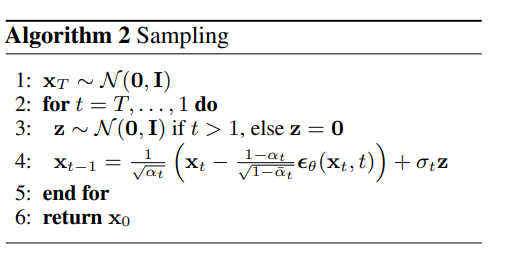


In [17]:
# sample using standard algorithm
@torch.no_grad()
def sample_ddpm(n_sample):
    nn_model.eval()
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 1, height, height).to(device)

    # TODO: complete the code here
    # Start from pure noise and in a loop from T down to 1, remove noise using the model at each step
    for t_step in reversed(range(timesteps)):
        # Create timestep tensor for all samples
        t = torch.full((n_sample,), t_step, device=device, dtype=torch.long)

        # Get beta_t, alpha_t, and alpha_bar_t for current timestep
        beta_t_curr = b_t[t_step]
        alpha_t_curr = a_t[t_step]
        alpha_bar_t_curr = a_bar_t[t_step]

        # Get alpha_bar_{t-1} (for t=0, use 1.0)
        if t_step > 0:
            alpha_bar_t_prev = a_bar_t[t_step - 1]
        else:
            alpha_bar_t_prev = torch.tensor(1.0, device=device)

        # Predict noise using the model (convert t to float for time embedding)
        eps_pred = nn_model(samples, t.float())

        # Compute coefficients for the mean
        # mean = (sqrt(alpha_bar_{t-1}) * beta_t / (1 - alpha_bar_t)) * x0_pred +
        #        (sqrt(alpha_t) * (1 - alpha_bar_{t-1}) / (1 - alpha_bar_t)) * x_t
        # First, estimate x0 from x_t and predicted noise
        x0_pred = (samples - torch.sqrt(1.0 - alpha_bar_t_curr) * eps_pred) / torch.sqrt(alpha_bar_t_curr)

        # Compute coefficients
        coef1 = torch.sqrt(alpha_bar_t_prev) * beta_t_curr / (1.0 - alpha_bar_t_curr)
        coef2 = torch.sqrt(alpha_t_curr) * (1.0 - alpha_bar_t_prev) / (1.0 - alpha_bar_t_curr)

        # Compute mean
        mean = coef1 * x0_pred + coef2 * samples

        if t_step > 0:
            # Add noise except for the last step (t=0)
            z = torch.randn_like(samples)
            sigma_t = torch.sqrt(beta_t_curr)
            samples = mean + sigma_t * z
        else:
            # For t=0, just use the mean (no noise)
            samples = mean

    return samples


## DDIM Sampling


In [18]:
# sample quickly using DDIM
@torch.no_grad()
def sample_ddim(n_sample):
    nn_model.eval()
    # x_T ~ N(0, 1), sample initial noise
    samples = torch.randn(n_sample, 1, height, height).to(device)

    n = 20
    step_size = timesteps // n

    # TODO: complete the code here
    # DDIM: deterministic sampling by skipping timesteps
    # Create a sequence of timesteps to sample from (e.g., [999, 949, 899, ..., 49, 0])
    timestep_sequence = list(range(timesteps - 1, -1, -step_size))

    for i, t_step in enumerate(timestep_sequence):
        # Create timestep tensor for all samples
        t = torch.full((n_sample,), t_step, device=device, dtype=torch.long)

        # Get alpha_bar_t for current timestep
        alpha_bar_t_curr = a_bar_t[t_step]

        # Get alpha_bar_{t-1} (for the next timestep in sequence)
        if i < len(timestep_sequence) - 1:
            t_next = timestep_sequence[i + 1]
            alpha_bar_t_prev = a_bar_t[t_next]
        else:
            # For the last step, use 1.0
            alpha_bar_t_prev = torch.tensor(1.0, device=device)

        # Predict noise using the model (convert t to float for time embedding)
        eps_pred = nn_model(samples, t.float())

        # Estimate x0 from x_t and predicted noise
        x0_pred = (samples - torch.sqrt(1.0 - alpha_bar_t_curr) * eps_pred) / torch.sqrt(alpha_bar_t_curr)

        # DDIM deterministic update: x_{t-1} = sqrt(alpha_bar_{t-1}) * x0_pred +
        #                                  sqrt(1 - alpha_bar_{t-1}) * eps_pred
        # No random noise added (deterministic)
        samples = torch.sqrt(alpha_bar_t_prev) * x0_pred + torch.sqrt(1.0 - alpha_bar_t_prev) * eps_pred

    return samples


## Results


In [28]:
samples = sample_ddpm(50)


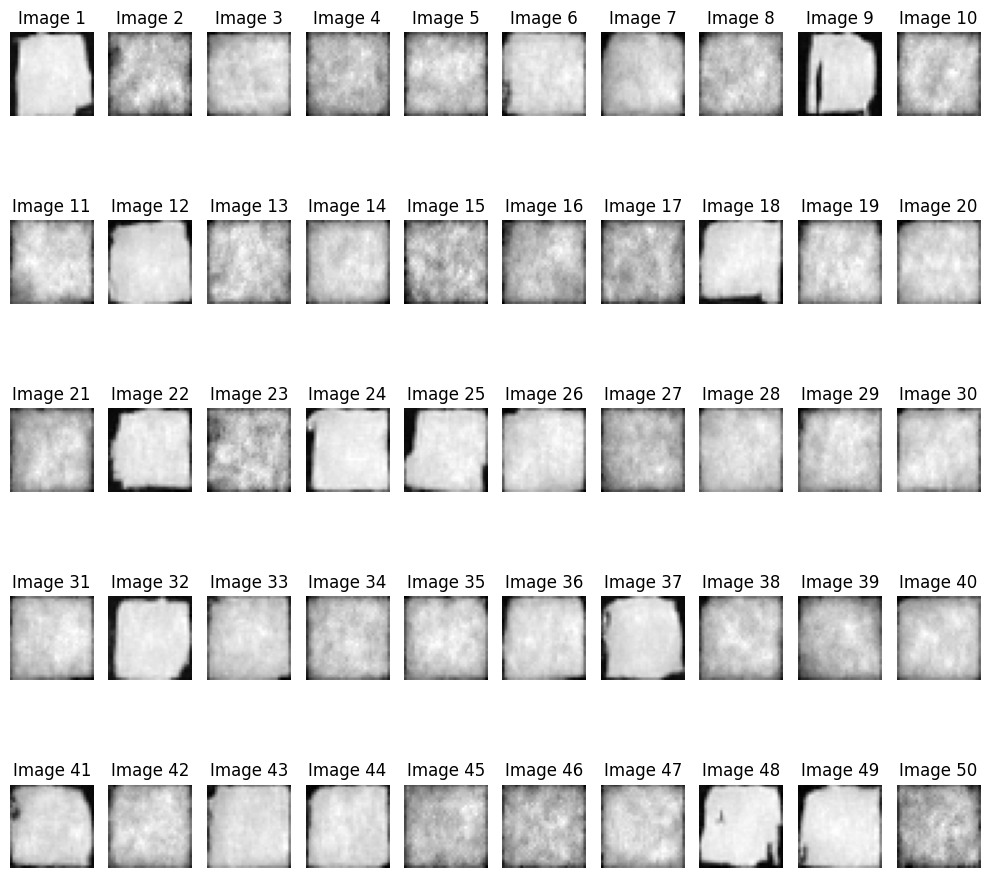

In [29]:
plot_sample(samples, 50, 5)


In [26]:
samples = sample_ddim(50)


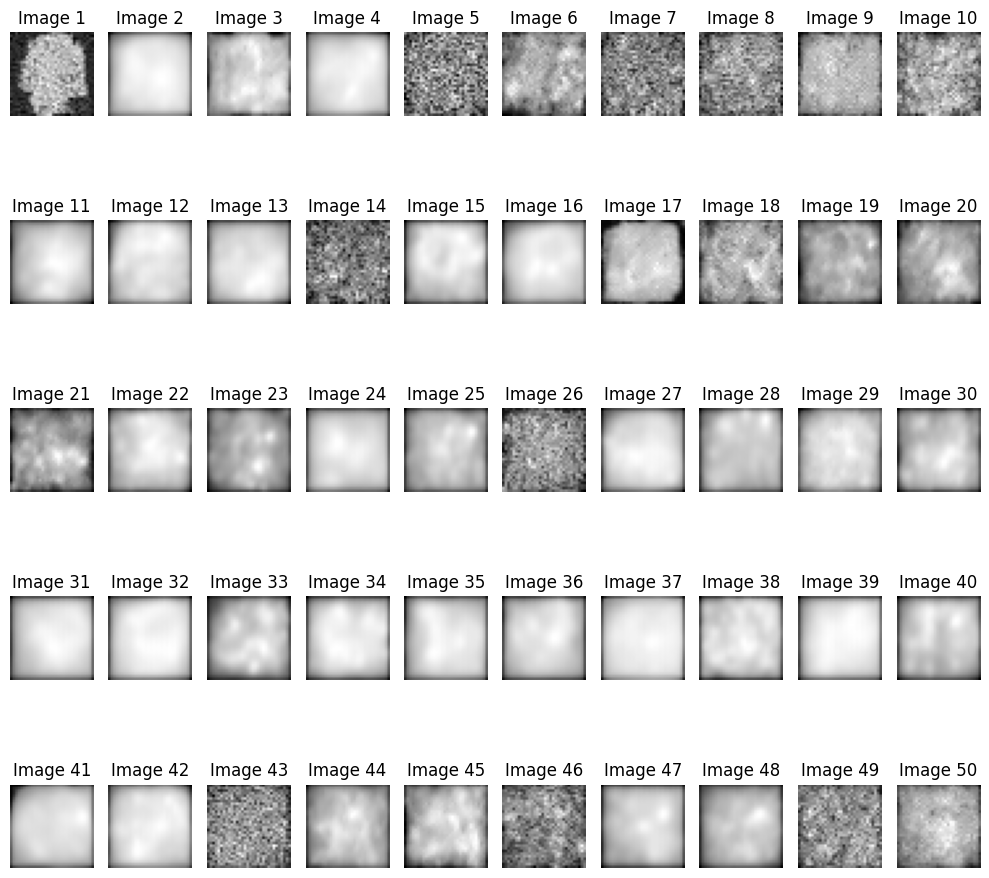

In [27]:
plot_sample(samples, 50, 5)


# Compare DDIM and DDPM Time


In [23]:
%timeit -r 1 sample_ddim(50)
%timeit -r 1 sample_ddpm(50)


404 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
20.3 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


# Evaluating the Generated Samples:


Now we want to evaluate our model. For this, we use the FID score.

First, read this link to become familiar with this metric and its usage in your code.


In [24]:
import os
from scipy import linalg

def calculate_fid_score(real_features, generated_features):
    """
    Calculate FID score between real and generated image features.

    Args:
        real_features: numpy array of shape (N, feature_dim) for real images
        generated_features: numpy array of shape (M, feature_dim) for generated images

    Returns:
        FID score (lower is better)
    """
    # Calculate mean and covariance for real features
    mu1 = np.mean(real_features, axis=0)
    sigma1 = np.cov(real_features, rowvar=False)

    # Calculate mean and covariance for generated features
    mu2 = np.mean(generated_features, axis=0)
    sigma2 = np.cov(generated_features, rowvar=False)

    # Calculate sum squared difference between means
    ssdiff = np.sum((mu1 - mu2) ** 2.0)

    # Calculate sqrt of product between cov
    covmean = linalg.sqrtm(sigma1.dot(sigma2))

    # Check and correct imaginary numbers from sqrt
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    # Calculate FID
    fid = ssdiff + np.trace(sigma1 + sigma2 - 2.0 * covmean)
    return fid


def extract_features_inception(images, model, device):
    """
    Extract features from images using Inception v3 model.
    Note: FashionMNIST is grayscale, so we need to convert to RGB for Inception.

    Args:
        images: tensor of shape (N, 1, H, W) in range [-1, 1]
        model: pretrained Inception v3 model
        device: device to run on

    Returns:
        features: numpy array of shape (N, feature_dim)
    """
    model.eval()
    features_list = []

    # Convert grayscale to RGB by repeating channels
    if images.shape[1] == 1:
        images_rgb = images.repeat(1, 3, 1, 1)
    else:
        images_rgb = images

    # Resize to 299x299 for Inception v3
    images_rgb = F.interpolate(images_rgb, size=(299, 299), mode='bilinear', align_corners=False)

    # Normalize to [0, 1] then to ImageNet stats
    images_rgb = (images_rgb + 1.0) / 2.0  # [-1, 1] -> [0, 1]

    # Manually apply normalization with mean and std
    # The original F.normalize does not accept mean and std arguments.
    # We need to reshape mean and std to (1, C, 1, 1) for broadcasting.
    mean_tensor = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
    std_tensor = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
    images_rgb = (images_rgb - mean_tensor) / std_tensor

    batch_size = 32
    with torch.no_grad():
        for i in range(0, len(images_rgb), batch_size):
            batch = images_rgb[i:i+batch_size].to(device)
            # Get features from the last pooling layer before classifier
            features = model(batch)
            features_list.append(features.cpu().numpy())

    return np.concatenate(features_list, axis=0)


# Load pretrained Inception v3 model for feature extraction
print("Loading Inception v3 model...")
try:
    inception_model = models.inception_v3(pretrained=True, transform_input=False)
except:
    # If pretrained=True doesn't work, try weights parameter (for newer torchvision)
    inception_model = models.inception_v3(weights='IMAGENET1K_V1', transform_input=False)

# Remove the final classification layer to get features
# Inception v3 has both fc and AuxLogits, we'll use the main fc
inception_model.fc = nn.Identity()
inception_model.AuxLogits = None  # Disable auxiliary classifier
inception_model = inception_model.to(device)
inception_model.eval()

# Generate samples for evaluation
print("Generating samples for FID evaluation...")
n_eval_samples = 1000

# Generate samples using DDPM
print("Generating DDPM samples...")
ddpm_samples = sample_ddpm(n_eval_samples)

# Generate samples using DDIM
print("Generating DDIM samples...")
ddim_samples = sample_ddim(n_eval_samples)

# Get real images from validation set
print("Loading real images...")
real_images_list = []
for i in range(min(n_eval_samples, len(val_dataset))):
    img, _ = val_dataset[i]
    real_images_list.append(img.unsqueeze(0))
real_images = torch.cat(real_images_list, dim=0).to(device)

# Extract features
print("Extracting features from real images...")
real_features = extract_features_inception(real_images, inception_model, device)

print("Extracting features from DDPM samples...")
ddpm_features = extract_features_inception(ddpm_samples, inception_model, device)

print("Extracting features from DDIM samples...")
ddim_features = extract_features_inception(ddim_samples, inception_model, device)

# Calculate FID scores
print("\nCalculating FID scores...")
fid_ddpm = calculate_fid_score(real_features, ddpm_features)
fid_ddim = calculate_fid_score(real_features, ddim_features)

print(f"\n{'='*50}")
print(f"FID Score Results:")
print(f"{'='*50}")
print(f"DDPM FID Score: {fid_ddpm:.2f}")
print(f"DDIM FID Score: {fid_ddim:.2f}")
print(f"{'='*50}")
print(f"\nNote: Lower FID score indicates better quality.")
print(f"FID measures the distance between feature distributions of real and generated images.")


Loading Inception v3 model...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Inception_V3_Weights.IMAGENET1K_V1`. You can also use `weights=Inception_V3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 200MB/s] 


Generating samples for FID evaluation...
Generating DDPM samples...
Generating DDIM samples...
Loading real images...
Extracting features from real images...
Extracting features from DDPM samples...
Extracting features from DDIM samples...

Calculating FID scores...

FID Score Results:
DDPM FID Score: 359.97
DDIM FID Score: 696.94

Note: Lower FID score indicates better quality.
FID measures the distance between feature distributions of real and generated images.
